In [6]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuracion el estilo visual
sns.set_theme(style="whitegrid")

# 1. Descarga datos históricos de Tesla usando 'yf' , rango de un año desde el 14 de octubre de 2025 hasta el 14 de octubre de 2026
df = yf.download('TSLA', start='2025-10-14', end='2026-10-14')
display(df.head())
# Limpiar y aplanar columnas que vienen en formato multi-índice
df = df.reset_index()
df.columns = [col[0].lower() if isinstance(col, tuple) else col.lower() for col in df.columns]

# Mostrar primeras filas
display(df.head())

# 2. Guardar archivor en carpeta data/ de tu proyecto
df.to_csv('../data/tesla_data.csv', index=False)
print("¡Datos de Tesla descargados y guardados en data/tesla_data.csv con éxito!")

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA
Date,,,,,
2025-10-14,429.239990,434.200012,417.859985,426.790009,72669400
2025-10-15,435.149994,440.510010,426.329987,434.899994,71558200
2025-10-16,428.750000,439.350006,421.309998,434.730011,77189900
2025-10-17,439.309998,441.459991,423.600006,425.500000,89331600
2025-10-20,447.429993,449.799988,440.609985,443.869995,63719000


,date,close,high,low,open,volume
0,2025-10-14,429.239990,434.200012,417.859985,426.790009,72669400
1,2025-10-15,435.149994,440.510010,426.329987,434.899994,71558200
2,2025-10-16,428.750000,439.350006,421.309998,434.730011,77189900
3,2025-10-17,439.309998,441.459991,423.600006,425.500000,89331600
4,2025-10-20,447.429993,449.799988,440.609985,443.869995,63719000


¡Datos de Tesla descargados y guardados en data/tesla_data.csv con éxito!


,date,close,high,low,open,volume
0,2025-10-14,429.239990,434.200012,417.859985,426.790009,72669400
1,2025-10-15,435.149994,440.510010,426.329987,434.899994,71558200
2,2025-10-16,428.750000,439.350006,421.309998,434.730011,77189900
3,2025-10-17,439.309998,441.459991,423.600006,425.500000,89331600
4,2025-10-20,447.429993,449.799988,440.609985,443.869995,63719000


<class 'pandas.DataFrame'>
RangeIndex: 251 entries, 0 to 250
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    251 non-null    str    
 1   close   251 non-null    float64
 2   high    251 non-null    float64
 3   low     251 non-null    float64
 4   open    251 non-null    float64
 5   volume  251 non-null    int64  
dtypes: float64(4), int64(1), str(1)
memory usage: 11.9 KB


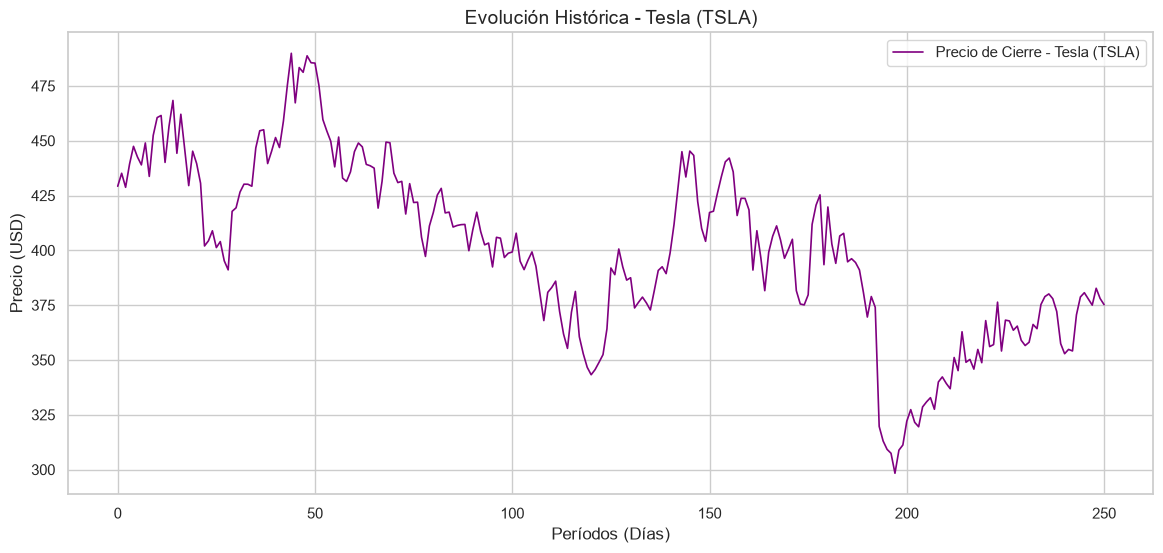

Total de registros: 251
-> Datos de Entrenamiento: 200
-> Datos de Evaluación (Held-out): 51
¡Conjuntos de entrenamiento y prueba de Tesla guardados con éxito!


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")

# 1. Cargar el dataset de Tesla desde la carpeta data/
df = pd.read_csv('../data/tesla_data.csv')

# Mostrar las primeras filas y estructura
display(df.head())
df.info()

# 2. Gráfica de la evolución histórica del precio de cierre (Close)
plt.figure(figsize=(14, 6))
plt.plot(df['close'], color='purple', linewidth=1.2, label='Precio de Cierre - Tesla (TSLA)')
plt.title('Evolución Histórica - Tesla (TSLA)', fontsize=14)
plt.xlabel('Períodos (Días)', fontsize=12)
plt.ylabel('Precio (USD)', fontsize=12)
plt.legend()
plt.show()

# 3. División cronológica (80% Entrenamiento / 20% Evaluación)
porcentaje_train = 0.8
corte = int(len(df) * porcentaje_train)

df_train = df.iloc[:corte].copy()
df_test = df.iloc[corte:].copy()

print(f"Total de registros: {len(df)}")
print(f"-> Datos de Entrenamiento: {len(df_train)}")
print(f"-> Datos de Evaluación (Held-out): {len(df_test)}")

# 4. Guardar los archivos segmentados para el entorno de Gymnasium
df_train.to_csv('../data/train_tesla.csv', index=False)
df_test.to_csv('../data/test_tesla.csv', index=False)
print("¡Conjuntos de entrenamiento y prueba de Tesla guardados con éxito!")